# 00 · What Machine Learning Is

*A Tour of Machine Learning* reworks material from Elie Rouphael's own MADIS Machine
Learning Workshop into eleven standalone notebooks, one idea each. This chapter 00 is the
map. It names what the eleven chapters have in common, and runs the one experiment every
one of them is secretly fighting: a model that fits its training data better and better
while predicting new data worse and worse.

**Objectives:** place each chapter in the families of machine learning; see the shared
recipe (data, model, loss, optimiser, evaluation); watch underfitting and overfitting
happen; and meet the two honest remedies, held-out evaluation and regularisation.

## 1. Learning a function from examples

A conventional program is written by hand: the rules go in, the answers come out. A
machine-learning program is given *examples* instead, and finds the rules itself. In
Mitchell's classic formulation, a program learns from experience $E$ at a task $T$, as
measured by a performance $P$, if its performance at $T$, measured by $P$, improves with
$E$.

The examples are pairs $(x_i, y_i)$, $i = 1, \dots, n$: an input $x_i$ (a car's weight, a
flower's measurements, a window of sensor readings) and, when it is known, the desired
output $y_i$. The tour's chapters fall into a few families:

- **Supervised learning**: every example comes with its answer $y_i$, and the goal is to
  predict the answer for new inputs. When $y$ is a number it is **regression**
  (chapter 01's CO2 emissions, chapter 08's next value of a sequence); when $y$ is a
  category it is **classification** (chapters 03, 04, 06, 07 and 11).
- **Unsupervised learning**: there are no answers, and the goal is to find structure.
  Chapter 05 groups customers into clusters; chapter 09 learns what *normal* sensor data
  look like, and flags what does not fit.
- **The machinery underneath**: chapter 02 is the calculus every training loop runs on,
  and chapter 10 builds the attention mechanism of transformers by hand, with no training
  at all.

Reinforcement learning, where an agent learns from rewards rather than examples, is a
third family that this tour does not cover.

## 2. The shared recipe

Almost every chapter follows the same five steps.

1. **Data**: examples $(x_i, y_i)$, split into a part to learn from and a part held back.
2. **Model**: a family of functions $f_\theta$, indexed by parameters $\theta$: a line in
   chapter 01, a tree ensemble in chapter 04, a neural network in chapter 06.
3. **Loss**: a number that says how badly $f_\theta$ fits the training data,
   $$ L(\theta) = \frac{1}{n}\sum_{i=1}^{n} \ell\big(y_i, f_\theta(x_i)\big), $$
   with a per-example loss $\ell$ such as the squared error $(y - \hat y)^2$.
4. **Optimiser**: a method to find the $\theta$ that makes $L$ small, in closed form
   (chapter 01) or step by step, by gradient descent (chapters 02 and 06).
5. **Evaluation**: the fitted model is judged on data it has **never seen**.

| Chapter | Family | What is minimised | How |
|---|---|---|---|
| 01 Linear regression | supervised, regression | squared error | closed form (normal equations) |
| 02 Minima and maxima | the calculus of training | a training loss $L(w)$ | calculus, and gradient descent |
| 03 Support vector machines | supervised, classification | hinge loss plus a margin term | a quadratic programme (scikit-learn's `SVC`) |
| 04 Random forest | supervised, classification | Gini impurity, split by split | greedy tree growing, and bagging |
| 05 K-means | unsupervised, clustering | inertia (within-cluster squared distance) | Lloyd's algorithm |
| 06 Neural network from scratch | supervised, classification | cross-entropy | gradient descent, with backpropagation |
| 07 Transfer learning | supervised, classification | cross-entropy | Adam, on reused features |
| 08 LSTM | supervised, regression on sequences | mean squared error | Adam |
| 09 Autoencoder | unsupervised, anomaly detection | reconstruction error | Adam, on normal data only |
| 10 Self-attention | the machinery of transformers | nothing: no training | plain arithmetic |
| 11 Federated learning | supervised, classification | cross-entropy (logistic regression) | gradient descent, averaged across clients |

Step 5 is the subtle one. A model is not useful because it fits the examples it was
given; it is useful if it predicts the ones it was not given. The rest of this chapter
shows why those two goals part ways.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import legendre

import mlutils
mlutils.set_style()

## 3. A first experiment: when more flexibility hurts

The data come from a smooth curve, $f(x) = \sin(2\pi x)$ on $[0, 1]$, observed with noise:
$y = f(x) + \varepsilon$, with $\varepsilon \sim \mathcal N(0, 0.3^2)$. We draw only
$n = 15$ training examples, and a large set of 5,000 fresh test examples from the same
distribution.

The models are polynomials of degree $d$, fitted by least squares. Degree 0 is a constant,
degree 1 a line, and each extra degree adds one coefficient, so the family grows more
flexible. (The polynomials are written in the Legendre basis on $[0, 1]$, which keeps the
least-squares problem well conditioned even at high degree; the fitted curves are the
same as with plain powers of $x$.)

In [2]:
f = lambda x: np.sin(2*np.pi*x)
SIGMA = 0.3

def sample(n, rng):
    x = rng.uniform(0, 1, n)
    return x, f(x) + rng.normal(0, SIGMA, n)

def features(x, degree):                       # Legendre polynomials of x mapped to [-1, 1]
    return legendre.legvander(2*x - 1, degree)

def fit(x, y, degree, lam=0.0):
    # least squares; with lam > 0, ridge regression (the constant term is not penalised)
    X = features(x, degree)
    if lam == 0:
        return np.linalg.lstsq(X, y, rcond=None)[0]
    P = np.eye(degree + 1); P[0, 0] = 0
    return np.linalg.solve(X.T @ X + lam*P, X.T @ y)

def rmse(pred, y):
    return np.sqrt(np.mean((pred - y)**2))

x_train, y_train = sample(15, np.random.default_rng(1))
x_test, y_test = sample(5000, np.random.default_rng(99))

print("degree   train RMSE   test RMSE")
for d in range(13):
    w = fit(x_train, y_train, d)
    print(f"{d:6d} {rmse(features(x_train, d) @ w, y_train):12.3f} {rmse(features(x_test, d) @ w, y_test):11.3f}")

degree   train RMSE   test RMSE
     0        0.773       0.766
     1        0.618       0.533
     2        0.571       0.595
     3        0.189       0.379
     4        0.188       0.381
     5        0.188       0.380
     6        0.156       0.451
     7        0.156       0.471
     8        0.140       1.496
     9        0.129       3.027
    10        0.126       4.204
    11        0.094      22.026
    12        0.088     111.637


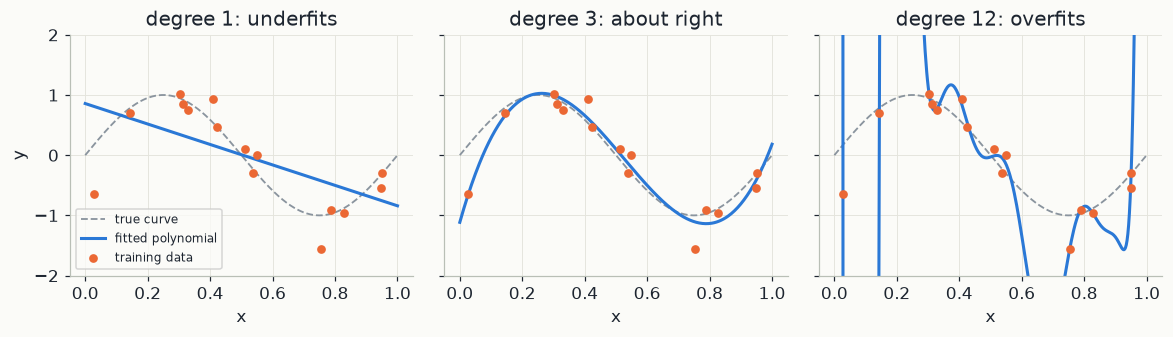

In [3]:
grid = np.linspace(0, 1, 400)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for a, d, name in zip(ax, (1, 3, 12), ("degree 1: underfits", "degree 3: about right", "degree 12: overfits")):
    w = fit(x_train, y_train, d)
    a.plot(grid, f(grid), color=mlutils.GREY, ls="--", lw=1.2, label="true curve")
    a.plot(grid, features(grid, d) @ w, color=mlutils.BLUE, lw=2, label="fitted polynomial")
    a.scatter(x_train, y_train, color=mlutils.ORANGE, s=22, zorder=3, label="training data")
    a.set_ylim(-2, 2); a.set_title(name); a.set_xlabel("x")
ax[0].set_ylabel("y"); ax[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

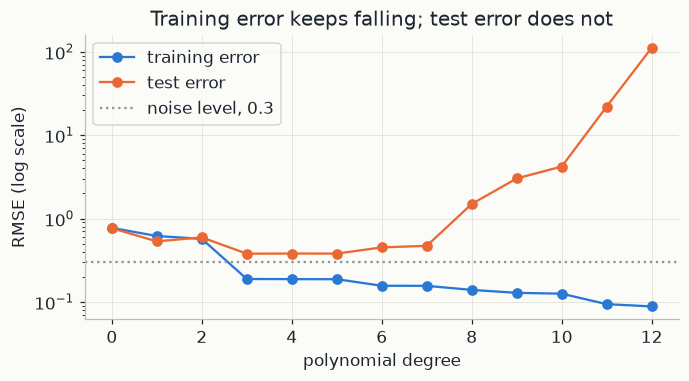

In [4]:
degrees = np.arange(13)
train_err = [rmse(features(x_train, d) @ fit(x_train, y_train, d), y_train) for d in degrees]
test_err = [rmse(features(x_test, d) @ fit(x_train, y_train, d), y_test) for d in degrees]
plt.figure(figsize=(6.4, 3.6))
plt.semilogy(degrees, train_err, "o-", color=mlutils.BLUE, label="training error")
plt.semilogy(degrees, test_err, "o-", color=mlutils.ORANGE, label="test error")
plt.axhline(SIGMA, color=mlutils.GREY, ls=":", label="noise level, 0.3")
plt.xlabel("polynomial degree"); plt.ylabel("RMSE (log scale)")
plt.title("Training error keeps falling; test error does not")
plt.legend(); plt.tight_layout(); plt.show()

The training error falls at every step: a more flexible family can always fit the 15
points at least as well. The test error tells a different story. It falls from degree 0
to degree 3, where it is lowest (0.379), then rises, slowly at first and then explosively:
at degree 12 the fitted curve passes close to every training point and swings wildly
between them, and its test error is over 100.

- At low degree the model **underfits**: it is too rigid to follow the curve, and errs
  even on its own training data.
- At high degree it **overfits**: it bends to follow the noise in the 15 points, which
  will not be there next time.
- The test error cannot fall below the **noise level**, 0.3, except by luck: no model
  can predict the random part of $y$. The training error can, and does, because a
  least-squares fit bends towards the particular noise in its 15 points: even at the
  right degree it is expected to sit a little under 0.3, and at degree 12 far under. A
  training error well below the noise level is a warning sign, not an achievement.

## 4. Bias and variance

Why does the test error first fall and then rise? Imagine repeating the whole experiment
on many independent training sets of 15 points. For a fixed input $x$, the prediction
$\hat f(x)$ changes from one training set to the next. Its expected squared error splits
into three parts:

$$ \mathbb E\big[(y - \hat f(x))^2\big] = \underbrace{\big(\mathbb E[\hat f(x)] - f(x)\big)^2}_{\text{bias}^2}
 + \underbrace{\mathrm{Var}\big[\hat f(x)\big]}_{\text{variance}} + \underbrace{\sigma^2}_{\text{noise}}. $$

The **bias** is how far the average prediction is from the truth: large for a rigid model.
The **variance** is how much the prediction moves with the training set: large for a
flexible model fitted to few points. The **noise** $\sigma^2 = 0.09$ is the floor. Below,
the two are measured on 2,000 training sets, averaged over $x$.

In [5]:
grid = np.linspace(0, 1, 201)

def training_sets(n, seeds):
    return [sample(n, np.random.default_rng(s)) for s in seeds]

def bias_variance(degree, sets):
    preds = np.array([features(grid, degree) @ fit(x, y, degree) for x, y in sets])
    bias2 = np.mean((preds.mean(axis=0) - f(grid))**2)
    return bias2, np.mean(preds.var(axis=0)), preds

sets = training_sets(15, range(5000, 7000))
print("degree      bias^2    variance   noise    expected test MSE")
for d in (0, 1, 3, 5):
    bias2, var, _ = bias_variance(d, sets)
    print(f"{d:6d} {bias2:11.4f} {var:11.4f} {SIGMA**2:7.2f} {bias2 + var + SIGMA**2:14.4f}")

degree      bias^2    variance   noise    expected test MSE
     0      0.4975      0.0397    0.09         0.6272
     1      0.2009      0.0492    0.09         0.3401


     3      0.0052      0.0661    0.09         0.1614
     5      0.0021      2.5767    0.09         2.6688


From degree 0 to degree 3, the bias collapses (0.50 to 0.005) while the variance grows
only a little (0.04 to 0.07): the extra flexibility is spent on following the curve. From
degree 3 to degree 5, the bias has little left to give, and the variance jumps from 0.07
to 2.6: the flexibility is now spent on following the noise. The sum is smallest at
degree 3.

That 2.6 deserves a closer look. It is an average over the 2,000 training sets, and at
degree 5 a few of them dominate it:

In [6]:
_, _, preds = bias_variance(5, sets)
share = np.mean((preds - preds.mean(axis=0))**2, axis=1)   # each set's share: they average to the variance
worst = np.argsort(share)[-20:]
gap = np.array([max(x.min(), 1 - x.max()) for x, _ in sets])   # the widest empty stretch at an end of [0, 1]
print(f"the worst 20 of the 2,000 training sets carry {share[worst].sum() / share.sum():.0%} of the variance")
print(f"their empty stretch at an end: median {np.median(gap[worst]):.2f}, against {np.median(gap):.2f} over all sets")

print("\nthe variance on ten other batches of 2,000 training sets:")
for b in range(1, 11):
    other = training_sets(15, range(5000 + 2000*b, 7000 + 2000*b))
    print(f"  batch {b:2d}:  degree 3 {bias_variance(3, other)[1]:.3f}   degree 5 {bias_variance(5, other)[1]:.2f}")

the worst 20 of the 2,000 training sets carry 61% of the variance
their empty stretch at an end: median 0.28, against 0.08 over all sets

the variance on ten other batches of 2,000 training sets:


  batch  1:  degree 3 0.091   degree 5 4.65


  batch  2:  degree 3 0.067   degree 5 4.13


  batch  3:  degree 3 0.071   degree 5 4.59


  batch  4:  degree 3 0.062   degree 5 2.20


...

  batch  6:  degree 3 0.114   degree 5 9.81


  batch  7:  degree 3 0.075   degree 5 12.23


  batch  8:  degree 3 0.083   degree 5 12.12


  batch  9:  degree 3 0.064   degree 5 5.65


  batch 10:  degree 3 0.079   degree 5 21.01


The worst 1% of the training sets carry 61% of the variance. They are the unlucky draws
that leave a wide empty stretch at one end of the interval (median 0.28, against 0.08 over
all sets); there the degree-5 polynomial has no data to hold it, and it shoots off.
Because a few rare sets dominate, the estimate itself is unsteady: the ten other batches
give anything from 2.20 to 21.01 at degree 5, while degree 3 stays between 0.06 and 0.11.
The exact number moves, but in every batch the degree-5 variance is dozens to hundreds of
times the degree-3 one. A flexible model fitted to few points does not just err a little more on average: now
and then, it fails badly.

This **bias-variance trade-off** is the shape behind every model choice in the tour: the
depth of chapter 04's trees, the number of chapter 05's clusters, the size of chapter 06's
hidden layer.

## 5. Choosing honestly: validation, and regularisation

We picked degree 3 by looking at the test error. That is cheating: once the test set has
been used to make a choice, its error is no longer an honest estimate of the error on new
data (exercise 3 measures how optimistic it becomes). The honest way is to choose using
the training data alone.

**Cross-validation** splits the training set into $k$ folds, fits on $k - 1$ of them,
measures the error on the one left out, and averages over the $k$ choices. It costs $k$
fits, but it never touches the test set.

**Regularisation** is the other lever: instead of limiting the degree, keep it high and
penalise large coefficients. Ridge regression minimises
$$ \sum_{i=1}^{n} \big(y_i - f_\theta(x_i)\big)^2 + \lambda \sum_{j \ge 1} \theta_j^2 , $$
the sum of squared errors plus $\lambda$ times the squared size of the coefficients (all
but the constant, which only shifts the curve up or down). The penalty pulls the wild
degree-12 fit back towards a smooth curve.

In [7]:
def cv_rmse(x, y, degree, k=5, lam=0.0):
    idx = np.arange(len(x)); errors = []
    for fold in np.array_split(idx, k):
        train = np.setdiff1d(idx, fold)
        w = fit(x[train], y[train], degree, lam)
        errors.append(np.mean((features(x[fold], degree) @ w - y[fold])**2))
    return np.sqrt(np.mean(errors))

cv = [cv_rmse(x_train, y_train, d) for d in range(10)]
print("5-fold CV RMSE by degree:", "  ".join(f"{d}: {e:.2f}" for d, e in enumerate(cv)))
print("cross-validation picks degree", int(np.argmin(cv)))

print("\nridge regression at degree 12")
print("  lambda    train RMSE   test RMSE")
for lam in (0, 1e-4, 1e-2, 1e-1, 1, 10):
    w = fit(x_train, y_train, 12, lam)
    print(f"  {lam:<8g} {rmse(features(x_train, 12) @ w, y_train):10.3f} {rmse(features(x_test, 12) @ w, y_test):11.3f}")

5-fold CV RMSE by degree: 0: 0.83  1: 0.77  2: 0.83  3: 0.29  4: 0.32  5: 0.48  6: 1.36  7: 4.71  8: 5.68  9: 146.50
cross-validation picks degree 3

ridge regression at degree 12
  lambda    train RMSE   test RMSE
  0             0.088     111.637
  0.0001        0.097       2.074
  0.01          0.123       0.644
  0.1           0.153       0.390
  1             0.252       0.414
  10            0.582       0.619


Cross-validation, using the 15 training points alone, picks degree 3, the same degree the
test set favoured. And ridge regression turns the degree-12 disaster (test error 111.6)
into a sensible model: with $\lambda = 0.1$ its test error is 0.390, close to degree 3's
0.379. Too much penalty underfits again ($\lambda = 10$: 0.619). The penalty strength is
itself a choice, made the same honest way (exercise 2).

The same two tools recur throughout the tour: chapter 03's soft-margin parameter, chapter
04's limits on tree depth and chapter 06's network size are all knobs on the same
trade-off, and every chapter judges its model on held-out data.

## 6. How to read the tour

The chapters are independent: read any one on its own, in any order. Each starts from the
idea, derives what is needed, runs it on data, and judges it against an honest baseline.
Chapters 01 and 02 are the foundations; 03 to 05 the classical toolkit; 06 to 10 deep
learning and modern architectures, from a network built in plain NumPy to attention built
by hand; and 11 closes with federated learning.

**Setup.** From the course folder:

```bash
pip install -r requirements.txt
jupyter lab
```

Every chapter needs `mlutils.py`, the shared plotting style, and most need a file from
`data/`; the full course download has both.

## Exercises

### Exercise 1: More data
Repeat the experiment of Section 3 with $n = 100$ training points instead of 15. How do
the two curves change, and which degree is best now?

<details><summary>Solution</summary>

```python
x100, y100 = sample(100, np.random.default_rng(1))
for d in range(13):
    w = fit(x100, y100, d)
    print(d, rmse(features(x100, d) @ w, y100), rmse(features(x_test, d) @ w, y_test))
```
With 100 points the test error is lowest at degree 5 (0.309, against 0.310 at degree 3),
and degree 12 costs only a little (0.373). More data shrinks the variance, so a more
flexible model can be afforded before it starts following the noise. The training error
still falls with every degree, and both errors now sit close to the noise level, 0.3.
</details>

### Exercise 2: Choosing the penalty
At degree 12 with the 15 training points, choose the ridge penalty $\lambda$ by 5-fold
cross-validation over a grid from $10^{-6}$ to $10^{2}$, and report the test error of the
chosen model.

<details><summary>Solution</summary>

```python
lams = 10.0**np.arange(-6, 2.01, 0.5)
cv_l = [cv_rmse(x_train, y_train, 12, lam=l) for l in lams]
best = lams[int(np.argmin(cv_l))]
w = fit(x_train, y_train, 12, best)
print(best, rmse(features(x_test, 12) @ w, y_test))
```
Cross-validation picks $\lambda = 0.3$, and its test error is 0.387, almost exactly that
of the best unregularised model (degree 3, 0.379). The cross-validation curve is U-shaped
in $\lambda$, as the test error was in the degree: too small a penalty lets the
polynomial overfit (CV RMSE 14.2 at $10^{-6}$), too large a penalty flattens it (0.82 at
$10^{2}$).
</details>

### Exercise 3: Leakage
Simulate the cheat of Section 5: on each of 1,000 runs, draw 15 training points and a
separate *small* test set of 15 points, pick the degree (0 to 9) with the lowest error on
that test set, and report that error. Compare it with the same model's error on 5,000 fresh
points.

<details><summary>Solution</summary>

```python
reported, true_err = [], []
for r in range(1000):
    rng = np.random.default_rng(20000 + r)
    x, y = sample(15, rng); xs, ys = sample(15, rng)
    errs = [rmse(features(xs, d) @ fit(x, y, d), ys) for d in range(10)]
    d_best = int(np.argmin(errs))
    reported.append(errs[d_best])
    true_err.append(rmse(features(x_test, d_best) @ fit(x, y, d_best), y_test))
print(np.median(reported), np.median(true_err), np.mean(np.array(reported) < np.array(true_err)))
```
The reported error has a median of 0.339 (mean 0.353); the same models' true error, on
fresh data, has a median of 0.357 (mean 0.422), and the report is optimistic in 64% of
the runs. Choosing the best of ten scores on a small test set picks, in part, the degree
that was *lucky* on those 15 points. Once a test set has been used to choose, it has
become part of the training, and a fresh test set is needed to report honestly.
</details>

### Exercise 4: Bias and variance with more data
Repeat the bias-variance measurement of Section 4 with $n = 60$, for degrees 0, 1, 3, 5
and 7. Which part of the error does more data reduce, and which degree is best now?

<details><summary>Solution</summary>

```python
sets60 = training_sets(60, range(5000, 7000))
for d in (0, 1, 3, 5, 7):
    bias2, var, _ = bias_variance(d, sets60)
    print(d, round(bias2, 4), round(var, 4), round(bias2 + var + SIGMA**2, 4))
```
With 60 points the bias is unchanged, since it measures how far the *average* fit is from
the truth: 0.50 at degree 0, 0.20 at degree 1. The variance falls sharply: at degree 5,
from 2.58 to 0.012. So the expected test MSE is now 0.102 at both degree 3 and degree 5
(a tie: 0.1019 against 0.1016, and other batches of training sets can swap the two) and
0.112 at degree 7, all close to the noise floor of 0.09. More data does not make a model
less biased; it makes it more stable, and so lets you afford more flexibility.
</details>

## Key takeaways

- Machine learning finds a function from examples. Supervised learning has the answers,
  unsupervised learning looks for structure, and the tour visits both.
- Every chapter follows one recipe: data, a model family, a loss, an optimiser, and an
  evaluation on held-out data.
- Training error always falls as a model grows more flexible; test error falls and then
  rises. The gap is overfitting, and the floor is the noise.
- The error splits into bias, variance and noise. Flexibility trades bias for variance;
  more data cuts the variance.
- Choose with cross-validation or a separate validation set, never with the test set, and
  regularise to keep a flexible model stable.

## References

1. T. M. Mitchell. *Machine Learning.* McGraw-Hill, 1997. (The definition of learning in Section 1.)
2. T. Hastie, R. Tibshirani, J. Friedman. *The Elements of Statistical Learning*, 2nd ed. Springer, 2009. doi:10.1007/978-0-387-84858-7 (Bias, variance and model selection, chapters 2 and 7.)
3. G. James, D. Witten, T. Hastie, R. Tibshirani. *An Introduction to Statistical Learning*, 2nd ed. Springer, 2021. doi:10.1007/978-1-0716-1418-1 (Cross-validation and the bias-variance trade-off, gently.)
4. C. M. Bishop. *Pattern Recognition and Machine Learning.* Springer, 2006. (The polynomial-curve-fitting example of Section 3.)
5. A. E. Hoerl, R. W. Kennard. *Ridge Regression: Biased Estimation for Nonorthogonal Problems.* Technometrics, 12(1):55-67, 1970. doi:10.1080/00401706.1970.10488634
6. M. Stone. *Cross-Validatory Choice and Assessment of Statistical Predictions.* Journal of the Royal Statistical Society B, 36(2):111-133, 1974. doi:10.1111/j.2517-6161.1974.tb00994.x
7. S. Geman, E. Bienenstock, R. Doursat. *Neural Networks and the Bias/Variance Dilemma.* Neural Computation, 4(1):1-58, 1992. doi:10.1162/neco.1992.4.1.1